# Import Library

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import warnings

# ---- Pengaturan tampilan ----
warnings.filterwarnings('ignore')         # sembunyikan peringatan teknis yang tidak penting
pd.set_option('display.width', 120)       # lebar tampilan tabel
pd.set_option('display.max_columns', 30)  # tampilkan sampai 30 kolom

plt.rcParams['figure.figsize'] = (12, 4)  # ukuran default grafik: lebar 12, tinggi 4
plt.rcParams['axes.grid'] = True          # tampilkan garis bantu
plt.rcParams['grid.alpha'] = 0.3          # garis bantu agak transparan
plt.rcParams['axes.spines.top'] = False   # hilangkan garis tepi atas (biar bersih)
plt.rcParams['axes.spines.right'] = False

print('Semua library siap ✅')

Semua library siap ✅


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_dir = '/content/drive/MyDrive/ecommerce_time_series_analysis-20260924T015743Z-1-001'

files = sorted(glob.glob(f'{data_dir}/sales_data_*.csv'))

df_list = [pd.read_csv(f) for f in files]
df = pd.concat(df_list, ignore_index=True)

df.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001"
1,NaN,NaN,NaN,NaN,NaN,NaN
2,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215"
3,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"
4,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186850 entries, 0 to 186849
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   Order ID          186305 non-null  object
 1   Product           186305 non-null  object
 2   Quantity Ordered  186305 non-null  object
 3   Price Each        186305 non-null  object
 4   Order Date        186305 non-null  object
 5   Purchase Address  186305 non-null  object
dtypes: object(6)
memory usage: 8.6+ MB


# Data Cleaning

In [ ]:
mask_header = df['Order ID'] == 'Order ID'
print(f'Baris header nyasar : {mask_header.sum():,}')

mask_empty = df.isna().all(axis=1)
print(f'Baris kosong total  : {mask_empty.sum():,}')

print(f'Duplikat persis     : {df.duplicated().sum():,}')

df[mask_header].head(3)

Baris header nyasar : 355
Baris kosong total  : 545
Duplikat persis     : 1,162


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
519,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
1149,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
1155,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address


In [ ]:
df_clean = df.copy()
n0 = len(df_clean)

df_clean = df_clean[df_clean['Order ID']!='Order ID']

df_clean = df_clean.dropna(how='all')

df_clean = df_clean.drop_duplicates()

df_clean['Quantity Ordered'] = pd.to_numeric(df_clean['Quantity Ordered'], errors='coerce')
df_clean['Price Each']       = pd.to_numeric(df_clean['Price Each'],       errors='coerce')
df_clean['Order Date']       = pd.to_datetime(df_clean['Order Date'],
                                        format='%m/%d/%y %H:%M', errors='coerce')

print('Gagal konversi (jadi kosong):')
print(f"  Quantity Ordered : {df_clean['Quantity Ordered'].isna().sum():,}")
print(f"  Price Each       : {df_clean['Price Each'].isna().sum():,}")
print(f"  Order Date       : {df_clean['Order Date'].isna().sum():,}")

df_clean = df_clean.dropna(subset=['Order Date', 'Quantity Ordered', 'Price Each'])

df_clean = df_clean.sort_values('Order Date').reset_index(drop=True)

print(f'\n{n0:,} baris  ->  {len(df_clean):,} baris  '
      f'(terbuang {n0 - len(df_clean):,} = {(n0-len(df_clean))/n0*100:.2f}%)')

Gagal konversi (jadi kosong):
  Quantity Ordered : 0
  Price Each       : 0
  Order Date       : 0

186,850 baris  ->  185,686 baris  (terbuang 1,164 = 0.62%)


In [ ]:
df_clean.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,147268,Wired Headphones,1,11.99,2019-01-01 03:07:00,"9 Lake St, New York City, NY 10001"
1,148041,USB-C Charging Cable,1,11.95,2019-01-01 03:40:00,"760 Church St, San Francisco, CA 94016"
2,149343,Apple Airpods Headphones,1,150.00,2019-01-01 04:56:00,"735 5th St, New York City, NY 10001"
3,149964,AAA Batteries (4-pack),1,2.99,2019-01-01 05:53:00,"75 Jackson St, Dallas, TX 75001"
4,149350,USB-C Charging Cable,2,11.95,2019-01-01 06:03:00,"943 2nd St, Atlanta, GA 30301"


In [ ]:
df_clean['Revenue'] = df_clean['Quantity Ordered'] * df_clean['Price Each']

parts = df_clean['Purchase Address'].str.split(',')
df_clean['City'] = parts.str[1].str.strip()
df_clean['State'] = parts.str[2].str.strip()

df_clean['CityState'] = df_clean['City'] + ' (' + df_clean['State'] + ')'

df_clean['Date'] = df_clean['Order Date'].dt.normalize()
df_clean['Hour'] = df_clean['Order Date'].dt.hour
df_clean['Month'] = df_clean['Order Date'].dt.to_period('M')

df_clean[['Order ID', 'Product', 'Quantity Ordered', 'Price Each',
          'Revenue', 'CityState', 'Order Date', 'Hour']].head()

,Order ID,Product,Quantity Ordered,Price Each,Revenue,CityState,Order Date,Hour
0,147268,Wired Headphones,1,11.99,11.99,New York City (NY 10001),2019-01-01 03:07:00,3
1,148041,USB-C Charging Cable,1,11.95,11.95,San Francisco (CA 94016),2019-01-01 03:40:00,3
2,149343,Apple Airpods Headphones,1,150.00,150.00,New York City (NY 10001),2019-01-01 04:56:00,4
3,149964,AAA Batteries (4-pack),1,2.99,2.99,Dallas (TX 75001),2019-01-01 05:53:00,5
4,149350,USB-C Charging Cable,2,11.95,23.90,Atlanta (GA 30301),2019-01-01 06:03:00,6


In [ ]:
print(f"Jumlah BARIS      : {len(df_clean):,}")
print(f"Jumlah ORDER unik : {df_clean['Order ID'].nunique():,}")
print(f"Selisih           : {len(df_clean) - df_clean['Order ID'].nunique():,} baris "
      f"berasal dari order multi-produk")

contoh = df_clean[df_clean['Order ID'].duplicated(keep=False)]['Order ID'].iloc[0]
print(f"\nContoh order multi-produk (Order ID {contoh}):")
df_clean[df_clean['Order ID'] == contoh][['Order ID', 'Product', 'Quantity Ordered', 'Revenue']]

Jumlah BARIS      : 185,686
Jumlah ORDER unik : 178,437
Selisih           : 7,249 baris berasal dari order multi-produk

Contoh order multi-produk (Order ID 144804):


,Order ID,Product,Quantity Ordered,Revenue
11,144804,iPhone,1,700.00
12,144804,Wired Headphones,1,11.99


In [ ]:
print(f"Rentang waktu : {df_clean['Order Date'].min()}  s/d  {df_clean['Order Date'].max()}")

harian_cek = df_clean.groupby('Date').agg(
    orders=('Order ID', 'nunique'),
    gmv=('Revenue', 'sum')
)
print(f'Jumlah hari   : {len(harian_cek)}')

print('\n5 hari dengan order TERSEDIKIT:')
print(harian_cek.nsmallest(5, 'orders'))

Rentang waktu : 2019-01-01 03:07:00  s/d  2020-01-01 05:13:00
Jumlah hari   : 366

5 hari dengan order TERSEDIKIT:
            orders       gmv
Date                        
2020-01-01      31   8670.29
2019-01-14     265  50078.53
2019-01-31     265  62383.13
2019-01-23     269  57572.45
2019-01-08     271  56100.52


In [ ]:
median_harian = harian_cek['orders'].median()
ambang = median_harian * 0.25

hari_parsial = harian_cek[harian_cek['orders'] < ambang].index
print(f'Median order/hari  : {median_harian:.0f}')
print(f'Ambang hari parsial: {ambang:.0f}')
print(f'Hari parsial       : {[str(d.date()) for d in hari_parsial]}')

df_clean = df_clean[~df_clean['Date'].isin(hari_parsial)]
print(f'\nSetelah dipotong: {df_clean["Date"].min().date()} s/d {df_clean["Date"].max().date()}'
      f'  ({df_clean["Date"].nunique()} hari, {len(df_clean):,} baris)')

Median order/hari  : 457
Ambang hari parsial: 114
Hari parsial       : ['2020-01-01']

Setelah dipotong: 2019-01-01 s/d 2019-12-31  (365 hari, 185,652 baris)


# EDA

## Q1 — Total revenue, jumlah order, jumlah barang, rata-rata per transaksi

In [ ]:
total_revenue = df_clean['Revenue'].sum()
total_order = df_clean['Order ID'].nunique()
total_quantity = df_clean['Quantity Ordered'].sum()

by_order = df_clean.groupby('Order ID').agg(
    qty = ('Quantity Ordered', 'sum'),
    rev = ('Revenue', 'sum')
)
avg_item = by_order['qty'].mean()
avg_rev = by_order['rev'].mean()

print('=' * 58)
print('  RINGKASAN PERFORMA')
print('=' * 58)
print(f'  Total revenue (GMV)      : ${total_revenue:>14,.2f}')
print(f'  Jumlah order             : {total_order:>15,}')
print(f'  Jumlah barang terjual    : {total_quantity:>15,}')
print(f'  Rata-rata item/transaksi : {avg_item:>15.2f}')
print(f'  Rata-rata spending/trx   : ${avg_rev:>14,.2f}')
print('=' * 58)

  RINGKASAN PERFORMA
  Total revenue (GMV)      : $ 34,456,867.65
  Jumlah order             :         178,406
  Jumlah barang terjual    :         208,771
  Rata-rata item/transaksi :            1.17
  Rata-rata spending/trx   : $        193.14


### Insight Q1

AOV-nya tinggi, tapi **rata-rata item per transaksi hanya ~1,17**.

**Artinya:** nilai order besar karena **harga satuannya mahal** (laptop, ponsel) —
bukan karena orang belanja banyak barang sekaligus.

**Konsekuensi bisnis:** ada ruang besar untuk **cross-sell** (menawarkan produk
pelengkap). Menaikkan rata-rata item dari 1,17 ke 1,30 saja sudah menambah puluhan ribu
dolar revenue — **tanpa perlu satu pun pelanggan baru**.


## Q2 — Jumlah order & GMV per hari, minggu, dan bulan

In [ ]:
d = df_clean.set_index('Order Date')

agg = {'orders' : ('Order ID', 'nunique'),'gmv' : ('Revenue', 'sum')}

harian = d.resample('D').agg(**agg)
mingguan = d.resample('W').agg(**agg)
bulanan = d.resample('ME').agg(**agg)

mingguan_hari =  d.resample('W')['Order ID'].apply(lambda x: x.index.normalize().nunique())
minggu_lengkap = mingguan_hari[mingguan_hari == 7].index
mingguan_baru = mingguan[mingguan.index.isin(minggu_lengkap)]

print('--- HARIAN (5 baris pertama) ---')
print(harian.head())
print(f'\nRata-rata: {harian["orders"].mean():.0f} order/hari, '
      f'${harian["gmv"].mean():,.0f} GMV/hari')

print('\n--- MINGGUAN ---')
print(mingguan_baru)

print('\n--- BULANAN ---')
print(bulanan)

--- HARIAN (5 baris pertama) ---
            orders       gmv
Order Date                  
2019-01-01     287  65681.94
2019-01-02     308  70663.20
2019-01-03     286  47046.20
2019-01-04     282  62000.22
2019-01-05     301  46524.63

Rata-rata: 489 order/hari, $94,402 GMV/hari

--- MINGGUAN ---
            orders         gmv
Order Date                    
2019-01-13    2104   409389.43
2019-01-20    2104   394921.11
2019-01-27    2134   426020.17
2019-02-03    2381   459570.62
2019-02-10    2832   565300.05
2019-02-17    2926   568199.28
2019-02-24    2880   535207.51
2019-03-03    3075   578306.44
2019-03-10    3297   640496.38
2019-03-17    3299   595771.07
2019-03-24    3311   629060.55
2019-03-31    3221   670872.96
2019-04-07    4040   774492.97
2019-04-14    4174   761454.22
2019-04-21    4127   805297.45
2019-04-28    4014   808694.68
2019-05-05    3669   764462.62
2019-05-12    3584   729309.99
2019-05-19    3651   695631.88
2019-05-26    3585   709784.55
2019-06-02    3399 

In [ ]:
bulanan_norm = bulanan.copy()
bulanan_norm['hari'] = d.resample('ME')['Order ID'].apply(
    lambda s: s.index.normalize().nunique())

bulanan_norm['gmv_per_hari']   = bulanan_norm['gmv']    / bulanan_norm['hari']
bulanan_norm['order_per_hari'] = bulanan_norm['orders'] / bulanan_norm['hari']

print(bulanan_norm.round(0))

if len(bulanan_norm) >= 2:              # if = kerjakan HANYA KALAU syaratnya benar
    a = bulanan_norm.iloc[0]            # baris pertama
    b = bulanan_norm.iloc[-1]           # baris terakhir
    print(f'\nPertumbuhan {bulanan_norm.index[0]:%b} -> {bulanan_norm.index[-1]:%b}:')
    print(f'  GMV total     : {(b["gmv"]/a["gmv"]-1)*100:+.1f}%')
    print(f'  GMV per hari  : {(b["gmv_per_hari"]/a["gmv_per_hari"]-1)*100:+.1f}%'
          f'   <-- angka yang benar')

            orders        gmv  hari  gmv_per_hari  order_per_hari
Order Date                                                       
2019-01-31    9262  1812743.0    31       58476.0           299.0
2019-02-28   11496  2200078.0    28       78574.0           411.0
2019-03-31   14549  2804973.0    31       90483.0           469.0
2019-04-30   17528  3389218.0    30      112974.0           584.0
2019-05-31   15836  3150616.0    31      101633.0           511.0
2019-06-30   12989  2576280.0    30       85876.0           433.0
2019-07-31   13761  2646461.0    31       85370.0           444.0
2019-08-31   11484  2241083.0    31       72293.0           370.0
2019-09-30   11202  2094466.0    30       69816.0           373.0
2019-10-31   19436  3734778.0    31      120477.0           627.0
2019-11-30   16859  3197875.0    30      106596.0           562.0
2019-12-31   24004  4608296.0    31      148655.0           774.0

Pertumbuhan Jan -> Dec:
  GMV total     : +154.2%
  GMV per hari  : +154.2%

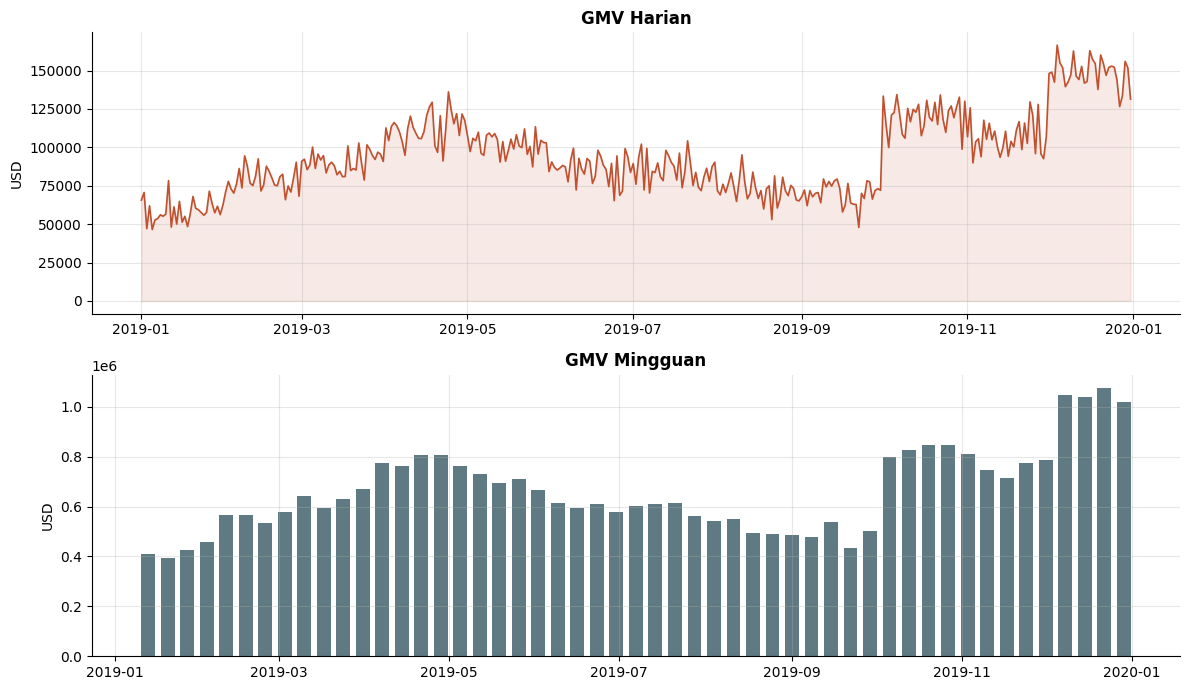

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7))    # 2 grafik bertumpuk

# --- Grafik atas: GMV harian ---
ax[0].plot(harian.index, harian['gmv'], lw=1.2, color='#C1502E')
ax[0].fill_between(harian.index, harian['gmv'],   # arsir area di bawah garis
                   alpha=0.12, color='#C1502E')
ax[0].set_title('GMV Harian', fontweight='bold')
ax[0].set_ylabel('USD')

# --- Grafik bawah: GMV mingguan ---
ax[1].bar(mingguan_baru.index, mingguan_baru['gmv'], width=5, color='#5F7A82')
ax[1].set_title('GMV Mingguan', fontweight='bold')
ax[1].set_ylabel('USD')

plt.tight_layout()    # rapikan jarak
plt.show()

## Q3 — Top produk & peluang bundling

In [ ]:
produk = df_clean.groupby('Product').agg(
    Revenue = ('Revenue', 'sum'),
    Quantity = ('Quantity Ordered', 'sum'),
    Order = ('Order ID', 'nunique')
)

print('--- TOP 10 BERDASARKAN REVENUE ---')
print(produk.nlargest(10, 'Revenue')[['Revenue', 'Quantity']].round(0))

print('\n--- TOP 10 BERDASARKAN Quantity ---')
print(produk.nlargest(10, 'Quantity')[['Quantity', 'Revenue']].round(0))

--- TOP 10 BERDASARKAN REVENUE ---
                              Revenue  Quantity
Product                                        
Macbook Pro Laptop          8030800.0      4724
iPhone                      4791500.0      6845
ThinkPad Laptop             4125959.0      4126
Google Phone                3316800.0      5528
27in 4K Gaming Monitor      2432758.0      6238
34in Ultrawide Monitor      2352898.0      6192
Apple Airpods Headphones    2344950.0     15633
Flatscreen TV               1443600.0      4812
Bose SoundSport Headphones  1342566.0     13427
27in FHD Monitor            1130625.0      7538

--- TOP 10 BERDASARKAN Quantity ---
                            Quantity    Revenue
Product                                        
AAA Batteries (4-pack)         30981    92633.0
AA Batteries (4-pack)          27615   106042.0
USB-C Charging Cable           23927   285928.0
Lightning Charging Cable       23163   346287.0
Wired Headphones               20520   246035.0
Apple Airpods He

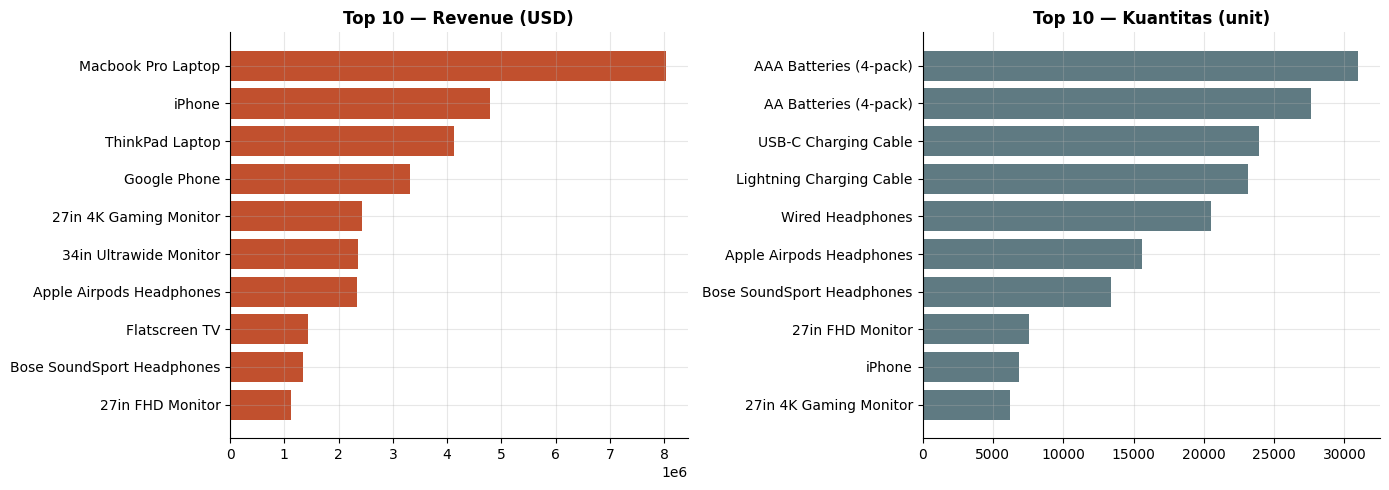

In [ ]:
top_rev = produk.nlargest(10, 'Revenue')
top_qty = produk.nlargest(10, 'Quantity')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))    # 1 baris, 2 kolom (bersebelahan)

# barh  = bar horizontal (batang mendatar), cocok untuk nama produk yang panjang
# [::-1] membalik urutan, supaya yang TERBESAR muncul di ATAS
ax[0].barh(top_rev.index[::-1], top_rev['Revenue'][::-1], color='#C1502E')
ax[0].set_title('Top 10 — Revenue (USD)', fontweight='bold')

ax[1].barh(top_qty.index[::-1], top_qty['Quantity'][::-1], color='#5F7A82')
ax[1].set_title('Top 10 — Kuantitas (unit)', fontweight='bold')

plt.tight_layout()
plt.show()

### Top 10 Produk

**Insight utama:**

1. Revenue ≠ Volume — Macbook Pro adalah penyumbang revenue #1, tapi bahkan tidak masuk top 10 kuantitas. Sebaliknya, baterai adalah produk terlaris (volume), tapi kontribusi revenue-nya kemungkinan kecil karena harga per unit murah.
2. Ada produk yang muncul di KEDUA daftar — iPhone, Apple Airpods, 27in FHD Monitor, 27in 4K Gaming Monitor muncul di kedua chart. Ini produk yang seimbang: cukup laris DAN cukup mahal, jadi berkontribusi signifikan di kedua metrik.


**Implikasi bisnis:**
1. Kalau fokus strategi ke profitabilitas/revenue → prioritaskan stok & promosi laptop/smartphone premium
2. Kalau fokus ke volume/traffic → baterai dan kabel charger adalah produk "pintu masuk" yang menarik banyak transaksi (bisa jadi strategi bundling — jual baterai murah untuk menarik pembeli, lalu cross-sell produk mahal)
3. Kandidat analisis lanjutan: hitung revenue per unit untuk tiap produk, atau cek apakah produk-produk baterai/kabel sering dibeli bersamaan dengan produk elektronik mahal dalam satu order (market basket analysis) — ini bisa mengonfirmasi dugaan pola "accessory attachment" (orang beli iPhone, sekalian beli charging cable).

In [ ]:
from itertools import combinations
from collections import Counter

multi = df_clean[df_clean['Order ID'].duplicated(keep=False)]

print(f'Order multi-produk: {multi["Order ID"].nunique():,} '
      f'dari {df_clean["Order ID"].nunique():,} '
      f'({multi["Order ID"].nunique()/df_clean["Order ID"].nunique()*100:.1f}%)')

pasangan = Counter()                        # siapkan kotak penghitung

for _, grup in multi.groupby('Order ID'):   # untuk tiap order...
    produk_unik = sorted(set(grup['Product']))   # daftar produk unik, diurutkan
    for pair in combinations(produk_unik, 2):    # untuk tiap pasangan...
        pasangan[pair] += 1                      # tambah hitungannya

# Ubah hasilnya jadi tabel yang enak dibaca
top_pasangan = pd.DataFrame(
    [(f'{a}  +  {b}', n) for (a, b), n in pasangan.most_common(10)],
    columns=['Pasangan Produk', 'Frekuensi']
)
top_pasangan

Order multi-produk: 6,876 dari 178,406 (3.9%)


,Pasangan Produk,Frekuensi
0,Lightning Charging Cable + iPhone,1010
1,Google Phone + USB-C Charging Cable,997
2,Wired Headphones + iPhone,462
3,Google Phone + Wired Headphones,422
4,Apple Airpods Headphones + iPhone,372
5,USB-C Charging Cable + Vareebadd Phone,368
6,Bose SoundSport Headphones + Google Phone,228
7,USB-C Charging Cable + Wired Headphones,203
8,Vareebadd Phone + Wired Headphones,149
9,Lightning Charging Cable + Wired Headphones,129


### Insight Q3 — rekomendasi bundling

Polanya jelas: **ponsel + aksesori yang sesuai konektornya**.

Pelanggan sudah membeli keduanya bersama **secara alami**. Tugas marketing tinggal
**membuatnya lebih mudah** — bukan menciptakan permintaan baru. Ini jenis rekomendasi
yang paling mudah disetujui, karena risikonya rendah.

> ⚠️ **Catatan penting:** produk dengan revenue tertinggi (laptop) **tidak muncul** di
> daftar pasangan. Pembeli laptop cenderung membeli tunggal.
>
> **Jangan paksa bundling di sana.** Memberi diskon bundel untuk produk yang toh akan
> dibeli sendirian = **membuang margin tanpa menambah penjualan**.

> 📌 **Catatan metodologi untuk laporanmu:** ini market basket analysis **sederhana**
> (sekadar menghitung frekuensi). Metode yang lebih lengkap (algoritma **Apriori**) juga
> menghitung **lift** dan **confidence** — untuk membedakan *"sering bersama karena
> memang berhubungan"* dari *"sering bersama karena dua-duanya memang laris"*.

## Q4 — Top 5 kota berdasarkan order & spending

In [ ]:
kota = df_clean.groupby('CityState').agg(
    orders=('Order ID', 'nunique'),
    gmv=('Revenue', 'sum')
)
kota['aov'] = kota['gmv'] / kota['orders']    # bikin kolom baru dari dua kolom lain

print('--- TOP 5 KOTA: JUMLAH ORDER ---')
print(kota.nlargest(5, 'orders').round(2))

print('\n--- TOP 5 KOTA: TOTAL SPENDING (GMV) ---')
print(kota.nlargest(5, 'gmv').round(2))

print('\n--- TOP 5 KOTA: RATA-RATA SPENDING PER ORDER (AOV) ---')
print(kota.nlargest(5, 'aov').round(2))

--- TOP 5 KOTA: JUMLAH ORDER ---
                          orders         gmv     aov
CityState                                           
San Francisco (CA 94016)   42887  8252258.67  192.42
Los Angeles (CA 90001)     28497  5447304.29  191.15
New York City (NY 10001)   23840  4660526.52  195.49
Boston (MA 02215)          19088  3657300.76  191.60
Atlanta (GA 30301)         14253  2794199.07  196.04

--- TOP 5 KOTA: TOTAL SPENDING (GMV) ---
                          orders         gmv     aov
CityState                                           
San Francisco (CA 94016)   42887  8252258.67  192.42
Los Angeles (CA 90001)     28497  5447304.29  191.15
New York City (NY 10001)   23840  4660526.52  195.49
Boston (MA 02215)          19088  3657300.76  191.60
Atlanta (GA 30301)         14253  2794199.07  196.04

--- TOP 5 KOTA: RATA-RATA SPENDING PER ORDER (AOV) ---
                          orders         gmv     aov
CityState                                           
Atlanta (GA 30301)   

### 💡 Insight Q4

Perhatikan: **daftar "order terbanyak" dan "AOV tertinggi" BERBEDA**.

- Kota juara volume → ordernya jauh terbanyak, tapi AOV-nya cuma menengah
- Kota juara AOV → ordernya cuma separuh, tapi tiap pelanggan belanja lebih mahal

**Artinya buat marketing: strateginya tidak boleh seragam.**

| Tipe kota | Strategi | Kenapa |
|---|---|---|
| Volume tinggi, AOV menengah | **Retensi & frekuensi** | Pelanggannya banyak — jaga supaya balik lagi |
| Volume menengah, AOV tinggi | **Produk premium & upsell** | Terbukti mau bayar lebih per transaksi |

> 💡 **Kenapa urutan GMV mirip urutan order?** Karena AOV antar kota di dataset ini
> sangat mirip. Jadi GMV hampir sepenuhnya ditentukan volume.
>
> **Ini sendiri sebuah temuan** — artinya perilaku belanja antar kota relatif seragam,
> dan perbedaan GMV murni soal **ukuran pasar**, bukan daya beli.

## Q5 — Rush hour: kapan penjualan paling aktif?

In [ ]:
jam = df_clean.groupby('Hour').agg(
    orders=('Order ID', 'nunique'),
    gmv=('Revenue', 'sum')
)

puncak = jam.nlargest(5, 'orders')
sepi   = jam.nsmallest(3, 'orders')

print('--- 5 JAM TERAMAI ---')
print(puncak)
print('\n--- 3 JAM TERSEPI ---')
print(sepi)

# Definisikan rush hour: jam yang ordernya >= 90% dari jam tersibuk
ambang_rush = jam['orders'].max() * 0.9
rush = jam[jam['orders'] >= ambang_rush].index.tolist()

print(f'\nRush hour (>= {ambang_rush:.0f} order): '
      f'{", ".join(f"{h:02d}.00" for h in sorted(rush))}')

--- 5 JAM TERAMAI ---
      orders         gmv
Hour                    
19     12377  2411971.14
12     12082  2314359.85
11     11882  2296619.84
20     11763  2280784.36
18     11761  2218374.01

--- 3 JAM TERSEPI ---
      orders        gmv
Hour                   
3        801  144683.04
4        810  162281.15
2       1192  232574.51

Rush hour (>= 11139 order): 11.00, 12.00, 13.00, 18.00, 19.00, 20.00


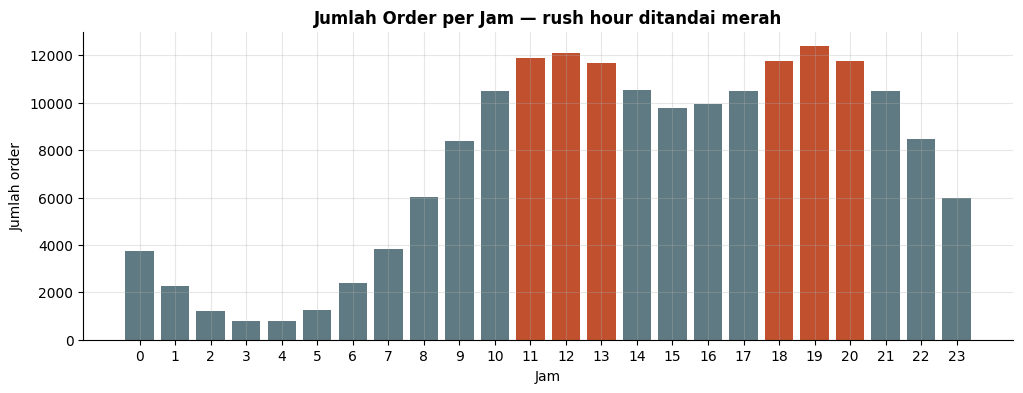

In [ ]:
warna = ['#C1502E' if v >= ambang_rush else '#5F7A82' for v in jam['orders']]

plt.figure(figsize=(12, 4))
plt.bar(jam.index, jam['orders'], color=warna)
plt.title('Jumlah Order per Jam — rush hour ditandai merah', fontweight='bold')
plt.xlabel('Jam')
plt.ylabel('Jumlah order')
plt.xticks(range(0, 24))    # tampilkan semua angka jam 0-23 di sumbu X
plt.show()

### 💡 Insight Q5

Polanya **bimodal** (dua punuk): satu di jam istirahat siang, satu di jam pulang kerja.
Punuk malam yang terbesar.

**Rekomendasi marketing:** jadwalkan push notification & flash sale **SEBELUM** punuk,
bukan di tengahnya. Orang perlu waktu untuk membuka aplikasi, melihat-lihat, dan
memutuskan. **Kirim tepat di puncak = terlambat.**

**Rekomendasi operasional:** jam-jam tersepi (dini hari) adalah **jendela aman untuk
maintenance & deploy** — risiko kehilangan transaksi paling kecil.

> ⚠️ **Keterbatasan yang harus kamu sadari:** dataset ini **tidak punya informasi zona
> waktu**. Kalau pembelinya tersebar di beberapa zona waktu (dan di data ini memang
> begitu — ada pantai timur dan barat Amerika), maka "jam 19.00" adalah **campuran**
> beberapa waktu lokal yang berbeda.
>
> **Tulis ini di laporanmu.**

# Analisis Trend dan Pola

In [ ]:
daily = df_clean.groupby('Date').agg(
    trx=('Order ID', 'nunique'),             # jumlah transaksi
    visitor=('Purchase Address', 'nunique'), # PROKSI jumlah visitor
    gmv=('Revenue', 'sum')                   # total nilai transaksi
).asfreq('D')                                # pastikan tiap hari ada barisnya

print(f'Periode        : {daily.index.min().date()} s/d {daily.index.max().date()}')
print(f'Jumlah hari    : {len(daily)}')
print(f'Tanggal bolong : {daily["trx"].isna().sum()}')   # idealnya 0
print()
print(daily[['trx', 'visitor']].describe().round(1))

Periode        : 2019-01-01 s/d 2019-12-31
Jumlah hari    : 365
Tanggal bolong : 0

         trx  visitor
count  365.0    365.0
mean   488.8    488.4
std    128.8    128.6
min    265.0    265.0
25%    391.0    391.0
50%    457.0    457.0
75%    575.0    574.0
max    843.0    842.0


### ⚠️ Kenapa `visitor` sangat mirip `trx`?

Karena di dataset ini hampir setiap order datang dari alamat berbeda. Jadi
"alamat unik per hari" ≈ "order per hari".

**Ini keterbatasan proksi kita, dan WAJIB ditulis di laporan.**

Visitor sesungguhnya (termasuk yang cuma melihat-lihat dan tidak jadi membeli) pasti
**jauh lebih banyak**, dan **rasio konversinya tidak bisa dihitung** dari data ini.

> 💡 Kalau kamu punya data web analytics sungguhan (Google Analytics, dsb.), ganti kolom
> ini dengan angka visitor asli — **kode selanjutnya tidak perlu diubah sama sekali.**

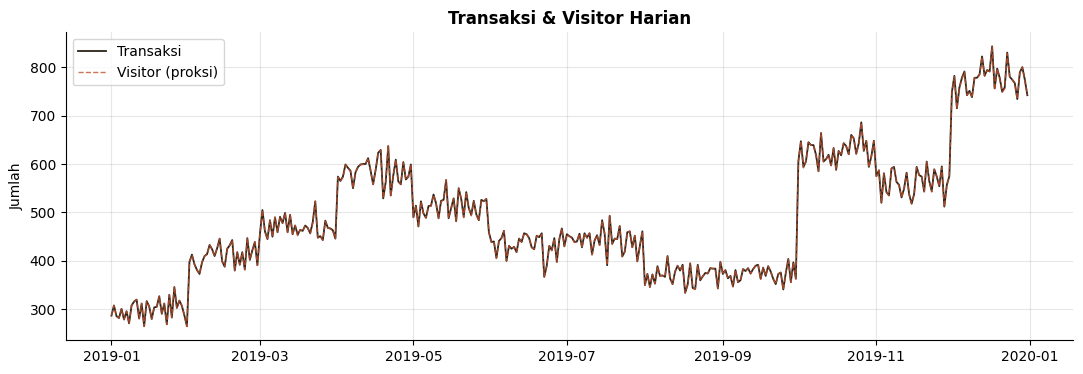

In [ ]:
plt.figure(figsize=(13, 4))
plt.plot(daily.index, daily['trx'], lw=1.3, color='#2A2318', label='Transaksi')
plt.plot(daily.index, daily['visitor'], lw=1.0, ls='--',
         color='#C1502E', alpha=0.8, label='Visitor (proksi)')
plt.title('Transaksi & Visitor Harian', fontweight='bold')
plt.ylabel('Jumlah')
plt.legend()
plt.show()

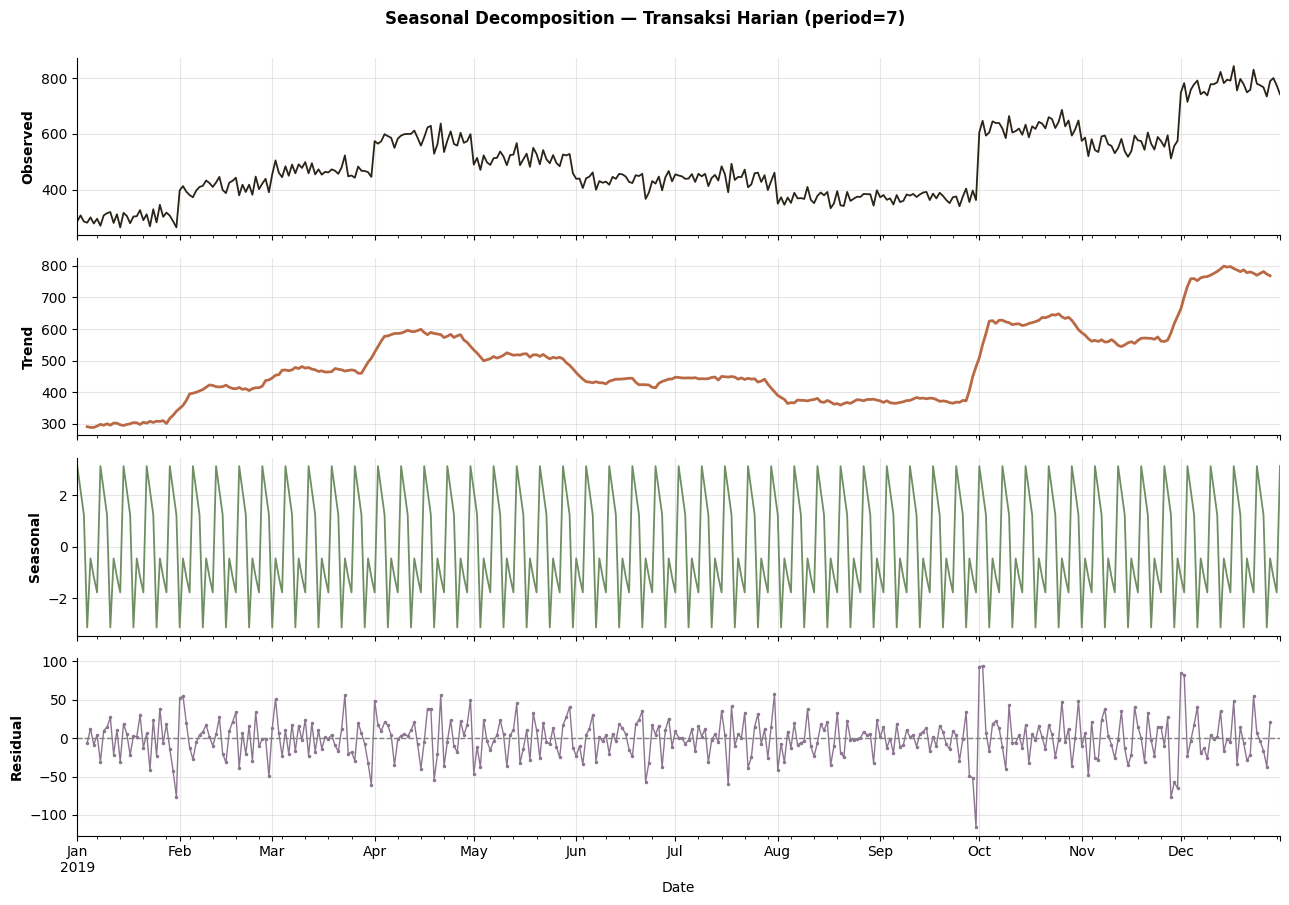

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose      # pecah trend/seasonal/residual
from statsmodels.tsa.stattools import adfuller               # uji stasioneritas (ADF)
from statsmodels.tsa.statespace.sarimax import SARIMAX       # model ARIMA / SARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing # model ETS

# Pecah deret transaksi jadi trend + seasonal + residual
dekomposisi = seasonal_decompose(daily['trx'], model='additive', period=7)

# Gambar 4 grafik bertumpuk, sumbu X-nya disamakan (sharex=True)
fig, ax = plt.subplots(4, 1, figsize=(13, 9), sharex=True)

dekomposisi.observed.plot(ax=ax[0], color='#2A2318', lw=1.3)
ax[0].set_ylabel('Observed', fontweight='bold')      # data asli

dekomposisi.trend.plot(ax=ax[1], color='#B96A45', lw=2)
ax[1].set_ylabel('Trend', fontweight='bold')         # arah jangka panjang

dekomposisi.seasonal.plot(ax=ax[2], color='#6F8F63', lw=1.3)
ax[2].set_ylabel('Seasonal', fontweight='bold')      # pola berulang

dekomposisi.resid.plot(ax=ax[3], color='#8C7590', lw=1, marker='.', ms=3)
ax[3].set_ylabel('Residual', fontweight='bold')      # sisa
ax[3].axhline(0, color='grey', ls='--', lw=1)        # garis nol sebagai acuan

fig.suptitle('Seasonal Decomposition — Transaksi Harian (period=7)',
             fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### 👀 Cara membaca keempat grafik itu

**1. Observed** — data aslinya, apa adanya.

**2. Trend** — arah jangka panjang.
   - Naik, turun, atau datar?
   - Seberapa jauh pergerakannya dari ujung ke ujung?

   > *Kenapa ujung kiri dan kanannya kosong?* Itu **normal**. Trend dihitung dengan
   > rata-rata bergerak 7 hari, jadi 3 hari di tiap ujung tidak punya cukup tetangga
   > untuk dihitung.

**3. Seasonal** — pola berulang.
   - Berulang rapi persis tiap 7 hari? (harusnya iya, karena kita set `period=7`)
   - **Seberapa TINGGI gelombangnya?** ← ini pertanyaan kuncinya

**4. Residual** — sisa yang tak terjelaskan.
   - Sudah acak di sekitar nol? **Bagus** — trend & seasonal sudah menangkap hampir
     semua informasi.
   - Masih kelihatan berpola? **Waspada** — ada sesuatu yang belum tertangkap.

---

### Sekarang kita ukur pakai angka, bukan pakai mata

Pertanyaan yang benar-benar penting:

> **Seberapa besar pengaruh musiman DIBANDINGKAN pergerakan trend?**

In [ ]:
# Amplitudo musiman = selisih puncak dan lembah gelombang seasonal
amplitudo_musiman = dekomposisi.seasonal.max() - dekomposisi.seasonal.min()

# Rentang trend = selisih titik tertinggi dan terendah garis trend
rentang_trend = dekomposisi.trend.max() - dekomposisi.trend.min()

print(f'Amplitudo musiman (puncak-lembah) : {amplitudo_musiman:6.1f} transaksi')
print(f'Rentang pergerakan trend          : {rentang_trend:6.1f} transaksi')
print(f'Rasio musiman : trend             = 1 : {rentang_trend/amplitudo_musiman:.1f}')
print()

if rentang_trend > amplitudo_musiman * 2:
    print('-> TREND jauh lebih dominan daripada seasonality.')
    print('   Temuan ini akan dibahas lagi di bagian Modelling.')
else:
    print('-> Seasonality cukup kuat dibanding trend.')

Amplitudo musiman (puncak-lembah) :    6.2 transaksi
Rentang pergerakan trend          :  510.3 transaksi
Rasio musiman : trend             = 1 : 81.7

-> TREND jauh lebih dominan daripada seasonality.
   Temuan ini akan dibahas lagi di bagian Modelling.


> 🔑 **Ini temuan paling penting**
>
> Pola musimannya **ada**, tapi **kecil** dibanding pergerakan trend.
>
> Artinya, komponen musiman mingguan hanya memberi tambahan **kecil**. Di bagian
> Modelling terlihat model bermusiman (SARIMA, Holt-Winters) memang terbaik, tetapi
> selisihnya dengan model trend tanpa musiman (Holt's linear) kurang dari 0,2 poin MAPE.

In [ ]:
nama_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']

# Ambil komponen seasonal, kelompokkan per hari-dalam-minggu, rata-ratakan
efek_hari = (pd.Series(dekomposisi.seasonal.values, index=daily.index)
             .groupby(daily.index.dayofweek)
             .mean())

# Ganti index dari angka (0-6) jadi nama hari
efek_hari.index = [nama_hari[i] for i in efek_hari.index]

print('Efek musiman per hari (selisih dari rata-rata, satuan transaksi):')
print(efek_hari.round(1).to_string())
print(f'\nHari teramai : {efek_hari.idxmax()}  ({efek_hari.max():+.1f})')
print(f'Hari tersepi : {efek_hari.idxmin()}  ({efek_hari.min():+.1f})')

Efek musiman per hari (selisih dari rata-rata, satuan transaksi):
Senin    -1.8
Selasa    3.1
Rabu      2.2
Kamis     1.2
Jumat    -3.1
Sabtu    -0.5
Minggu   -1.2

Hari teramai : Selasa  (+3.1)
Hari tersepi : Jumat  (-3.1)


### 👀 Cara membacanya

- Batang di **atas** garis nol = hari itu biasanya **lebih ramai** dari rata-rata
- Batang di **bawah** garis nol = biasanya **lebih sepi**

> **Gunanya buat bisnis:** kalau kamu tahu hari mana yang selalu lebih sepi, kamu bisa
> menjadwalkan promo **di situ** — bukan di hari yang toh sudah ramai sendiri.

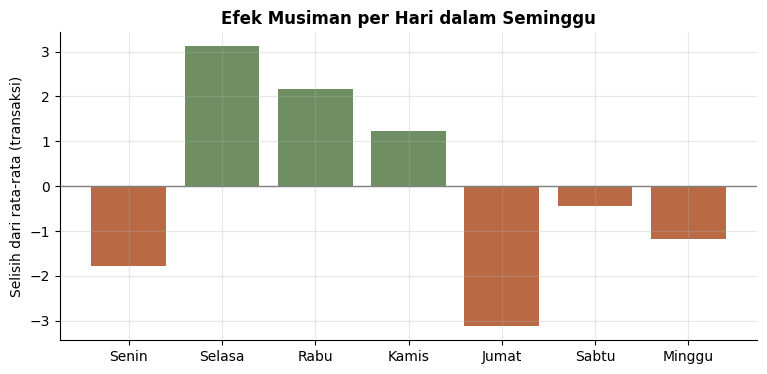

In [ ]:
# Hijau kalau di atas rata-rata, oranye kalau di bawah
warna_hari = ['#6F8F63' if v >= 0 else '#B96A45' for v in efek_hari]

plt.figure(figsize=(9, 4))
plt.bar(efek_hari.index, efek_hari.values, color=warna_hari)
plt.axhline(0, color='grey', lw=1)     # garis nol = rata-rata
plt.title('Efek Musiman per Hari dalam Seminggu', fontweight='bold')
plt.ylabel('Selisih dari rata-rata (transaksi)')
plt.show()

In [ ]:
def uji_adf(series, nama):
    # def = mendefinisikan fungsi sendiri, supaya tidak menulis kode yang sama 3x
    hasil = adfuller(series.dropna())    # dropna() buang nilai kosong dulu
    stat, p = hasil[0], hasil[1]         # ambil dua nilai pertama dari hasilnya
    status = 'STASIONER ✅' if p <= 0.05 else 'TIDAK stasioner ❌'
    print(f'{nama:<28} ADF = {stat:>7.3f} | p-value = {p:.4f}  -> {status}')
    return p                             # return = kirim balik nilainya ke pemanggil

print('UJI STASIONERITAS (ADF Test)')
print('-' * 72)
p0 = uji_adf(daily['trx'],               'Data asli')
p1 = uji_adf(daily['trx'].diff(),        'Setelah differencing 1x')
p2 = uji_adf(daily['trx'].diff().diff(), 'Setelah differencing 2x')
print('-' * 72)

# Tentukan d: berapa kali differencing yang dibutuhkan
d_optimal = 0 if p0 <= 0.05 else (1 if p1 <= 0.05 else 2)
print(f'\n=> Gunakan d = {d_optimal} pada model ARIMA')

UJI STASIONERITAS (ADF Test)
------------------------------------------------------------------------
Data asli                    ADF =  -1.131 | p-value = 0.7025  -> TIDAK stasioner ❌
Setelah differencing 1x      ADF = -14.808 | p-value = 0.0000  -> STASIONER ✅
Setelah differencing 2x      ADF =  -8.565 | p-value = 0.0000  -> STASIONER ✅
------------------------------------------------------------------------

=> Gunakan d = 1 pada model ARIMA


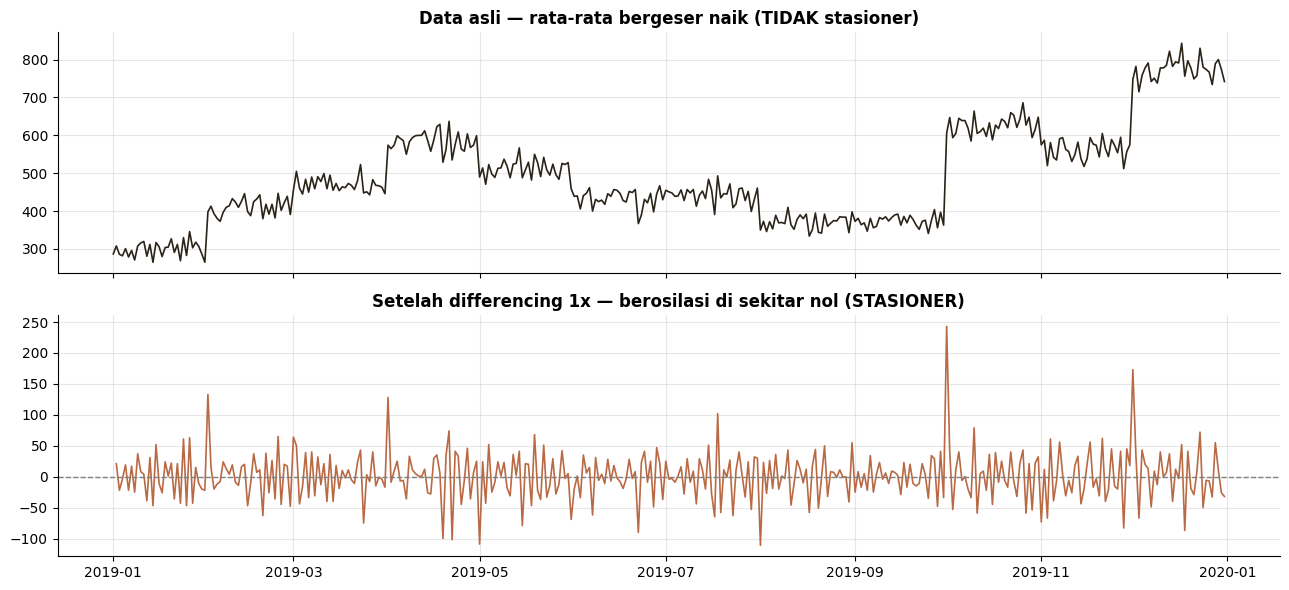

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

ax[0].plot(daily.index, daily['trx'], color='#2A2318', lw=1.2)
ax[0].set_title('Data asli — rata-rata bergeser naik (TIDAK stasioner)',
                fontweight='bold')

ax[1].plot(daily.index, daily['trx'].diff(), color='#B96A45', lw=1.2)
ax[1].axhline(0, color='grey', ls='--', lw=1)
ax[1].set_title('Setelah differencing 1x — berosilasi di sekitar nol (STASIONER)',
                fontweight='bold')

plt.tight_layout()
plt.show()

### 👀 Bandingkan kedua grafik

- **Atas** — garisnya jelas merangkak naik. Rata-rata di awal periode **berbeda** dengan
  rata-rata di akhir → **tidak stasioner**
- **Bawah** — naik-turun di sekitar garis nol, tanpa arah yang jelas → **stasioner**

Inilah yang dimaksud "membuat data stasioner dengan differencing".

# Modelling

## Forecast Transaksi

In [ ]:
HORIZON = 30    # panjang periode uji sekaligus panjang forecast ke depan (hari)

y = daily['trx'].astype(float)     # astype(float) -> pastikan bertipe desimal,
                                   # karena beberapa model membutuhkannya

train = y[:-HORIZON]     # semua KECUALI 30 hari terakhir
test  = y[-HORIZON:]     # HANYA 30 hari terakhir

print(f'Total  : {len(y)} hari')
print(f'Train  : {len(train)} hari  '
      f'({train.index.min().date()} s/d {train.index.max().date()})')
print(f'Test   : {len(test)} hari  '
      f'({test.index.min().date()} s/d {test.index.max().date()})')

Total  : 365 hari
Train  : 335 hari  (2019-01-01 s/d 2019-12-01)
Test   : 30 hari  (2019-12-02 s/d 2019-12-31)


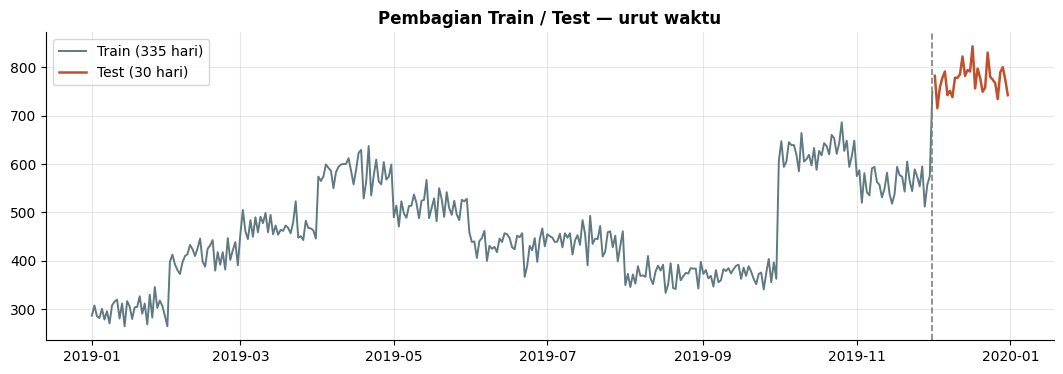

In [ ]:
plt.figure(figsize=(13, 4))
plt.plot(train.index, train, color='#5F7A82', lw=1.4, label=f'Train ({len(train)} hari)')
plt.plot(test.index,  test,  color='#C1502E', lw=1.8, label=f'Test ({len(test)} hari)')
plt.axvline(train.index[-1], color='grey', ls='--', lw=1.2)   # garis pemisah
plt.title('Pembagian Train / Test — urut waktu', fontweight='bold')
plt.legend()
plt.show()

In [ ]:
# Ulangi 7 nilai terakhir dari train sebanyak yang dibutuhkan
pred_naive = np.array([train.iloc[-7 + (i % 7)] for i in range(HORIZON)])

# Tampilkan berdampingan dengan aktualnya
pd.DataFrame({'aktual': test.values, 'naive': pred_naive},
             index=test.index).head()

,aktual,naive
Date,,
2019-12-02,782.0,574.0
2019-12-03,715.0,554.0
2019-12-04,758.0,595.0
2019-12-05,778.0,512.0
2019-12-06,791.0,557.0


## Baseline — model "bodoh" sebagai wasit

Sebelum membangun model canggih, buat dulu tebakan **paling sederhana** yang bisa kamu
bayangkan:

> **"Besok = hari yang sama minggu lalu."**

Tidak ada matematika. Tidak ada parameter. Cuma **menyalin**.

### Kenapa ini penting?

Karena angka MAPE baru bermakna jika ada pembandingnya. Model yang MAPE-nya terlihat
bagus belum tentu berguna kalau tebakan sederhana ini ternyata sama baiknya.
Di data ini baseline meleset **24,26%** (MAPE), jadi itulah angka yang harus dikalahkan.

> 🔑 **Aturan emas:** model yang **kalah dari baseline** berarti menambah kerumitan
> tanpa menambah nilai. **Jangan dipakai.**

Baseline **tidak ikut dipilih** sebagai model final — perannya cuma jadi **wasit**.

In [ ]:
# Daftar kombinasi yang akan dicoba
kandidat_order    = [(1,1,1), (2,1,1), (1,1,2), (0,1,1), (1,0,1), (2,1,2)]
kandidat_seasonal = [(1,1,1,7), (1,0,1,7), (0,1,1,7)]

hasil_grid = []                              # tempat menampung hasil

for order in kandidat_order:                 # perulangan BERSARANG:
    for sorder in kandidat_seasonal:         # tiap order dicoba dengan tiap sorder
        try:
            m = SARIMAX(train,
                        order=order,
                        seasonal_order=sorder,
                        enforce_stationarity=False,    # longgarkan syarat teknis,
                        enforce_invertibility=False    # supaya lebih banyak yang jalan
                        ).fit(disp=False)              # disp=False: jangan cetak proses
            hasil_grid.append({'order': order, 'seasonal_order': sorder, 'aic': m.aic})
        except Exception:
            pass          # kalau kombinasi ini gagal, lewati saja

# Ubah jadi tabel, urutkan dari AIC terkecil
grid_df = pd.DataFrame(hasil_grid).sort_values('aic').reset_index(drop=True)

print('5 kombinasi dengan AIC terkecil:')
print(grid_df.head())

# Ambil yang terbaik (baris ke-0 setelah diurutkan)
best_order  = grid_df.loc[0, 'order']
best_sorder = grid_df.loc[0, 'seasonal_order']
print(f'\nTerpilih: SARIMA{best_order}x{best_sorder}  (AIC = {grid_df.loc[0,"aic"]:.1f})')

5 kombinasi dengan AIC terkecil:
       order seasonal_order          aic
0  (1, 1, 2)   (0, 1, 1, 7)  3194.436334
1  (2, 1, 2)   (0, 1, 1, 7)  3194.988358
2  (1, 1, 2)   (1, 1, 1, 7)  3196.168335
3  (0, 1, 1)   (0, 1, 1, 7)  3200.401364
4  (0, 1, 1)   (1, 1, 1, 7)  3202.194788

Terpilih: SARIMA(1, 1, 2)x(0, 1, 1, 7)  (AIC = 3194.4)


In [ ]:
# Latih model dengan parameter terbaik hasil grid search
model_sarima = SARIMAX(train,
                       order=best_order,
                       seasonal_order=best_sorder,
                       enforce_stationarity=False,
                       enforce_invertibility=False).fit(disp=False)

# Ramalkan sebanyak HORIZON hari ke depan (periode test)
pred_sarima = model_sarima.forecast(HORIZON)

# Tampilkan tabel koefisien model
print(model_sarima.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9735      0.014    -71.640      0.000      -1.000      -0.947
ma.L1          0.4972    303.233      0.002      0.999    -593.828     594.822
ma.L2         -0.5028    152.470     -0.003      0.997    -299.339     298.333
ma.S.L7       -1.0000    303.211     -0.003      0.997    -595.282     593.282
sigma2      1249.6193      0.259   4822.289      0.000    1249.111    1250.127


**Yang perlu kamu lihat sebagai pemula:** kolom **`P>|z|`**.

Kalau **banyak** koefisien p-value-nya besar (> 0,05), artinya model ini punya
**terlalu banyak parameter yang tidak berguna** — tanda kemungkinan **overfitting**.

> 💡 Sebagai pemula kamu **belum perlu** menafsirkan angka koefisiennya satu per satu.
> Yang penting: **modelnya berhasil dilatih**, dan nanti kita nilai dari **MAPE**-nya.

In [ ]:
# Simpan pengaturan tiap varian ETS dalam satu dictionary
spesifikasi_ets = {
    'ETS Simple (SES)':              dict(trend=None,  seasonal=None),
    "ETS Double (Holt's linear)":    dict(trend='add', seasonal=None),
    'ETS Double damped':             dict(trend='add', seasonal=None, damped_trend=True),
    'ETS Triple Holt-Winters (m=7)': dict(trend='add', seasonal='add', seasonal_periods=7),
    'ETS Triple damped (m=7)':       dict(trend='add', seasonal='add', seasonal_periods=7,
                                          damped_trend=True),
}

model_ets = {}     # tempat menyimpan model yang sudah dilatih
pred_ets  = {}     # tempat menyimpan hasil prediksinya

for nama, spec in spesifikasi_ets.items():        # .items() -> ambil kunci DAN nilainya
    fit = ExponentialSmoothing(train,
                               initialization_method='estimated',
                               **spec).fit()      # **spec membongkar pengaturannya
    model_ets[nama] = fit
    pred_ets[nama]  = fit.forecast(HORIZON)

    # Tampilkan parameter yang ditemukan model secara otomatis
    par = []
    for kunci, label in [('smoothing_level', 'α'), ('smoothing_trend', 'β'),
                         ('smoothing_seasonal', 'γ'), ('damping_trend', 'φ')]:
        v = fit.params.get(kunci)                  # .get() -> ambil; kalau tidak ada, None
        if v is not None and not pd.isna(v):
            par.append(f'{label}={v:.3f}')
    print(f'{nama:<32} {"  ".join(par)}')

ETS Simple (SES)                 α=0.501
ETS Double (Holt's linear)       α=0.497  β=0.000
ETS Double damped                α=0.495  β=0.000  φ=0.988
ETS Triple Holt-Winters (m=7)    α=0.498  β=0.000  γ=0.000
ETS Triple damped (m=7)          α=0.451  β=0.084  γ=0.000  φ=0.800


### 👀 Perhatikan nilai α (alpha) yang ditemukan model

| Nilai α | Artinya |
|---|---|
| Mendekati **1** | Model sangat mengandalkan data **terbaru**, hampir mengabaikan yang lama |
| Mendekati **0** | Model merata-ratakan **jauh ke belakang** — lebih halus, tapi lebih lambat bereaksi |

> 💡 **Ini bukan sekadar angka teknis.** α yang tinggi memberitahumu bahwa **data terbaru
> jauh lebih informatif** daripada data lama — yang biasanya berarti ada **perubahan
> perilaku** atau **pertumbuhan cepat** di periode terakhir.
>
> Angka ini bisa kamu sebut di laporan sebagai bukti kuantitatif bahwa bisnisnya sedang
> berubah cepat.

In [ ]:
def hitung_metrik(aktual, prediksi):
    # np.asarray -> ubah jadi array numpy, supaya perhitungannya cepat & seragam
    a = np.asarray(aktual,   dtype=float)
    f = np.asarray(prediksi, dtype=float)
    return {
        'MAE':  np.mean(np.abs(a - f)),                  # abs  = nilai mutlak
        'RMSE': np.sqrt(np.mean((a - f) ** 2)),          # sqrt = akar, ** 2 = kuadrat
        'MAPE': np.mean(np.abs((a - f) / a)) * 100,      # dibagi aktual -> jadi persen
    }

# Kumpulkan SEMUA prediksi ke dalam satu dictionary
semua_prediksi = {'SARIMA' + str(best_order) + 'x' + str(best_sorder): pred_sarima}
semua_prediksi.update(pred_ets)      # .update() -> gabungkan dictionary lain ke dalamnya

# Hitung metrik untuk tiap model, ubah jadi tabel
evaluasi = pd.DataFrame(
    {nama: hitung_metrik(test, p) for nama, p in semua_prediksi.items()}
).T.sort_values('MAPE')              # .T = transpose (tukar baris & kolom)

# Hitung juga untuk baseline (dipisah, karena TIDAK ikut dipilih)
baseline = pd.DataFrame({'Baseline naif (lag-7)': hitung_metrik(test, pred_naive)}).T

print('=' * 74)
print(f'  HASIL EVALUASI — JUMLAH TRANSAKSI (test {len(test)} hari)')
print('=' * 74)
print(pd.concat([evaluasi, baseline]).round(2).to_string())
print('=' * 74)

model_terbaik = evaluasi.index[0]    # baris pertama = MAPE terkecil
print(f'\n⭐ Model terbaik (MAPE terkecil): {model_terbaik}'
      f'  — MAPE {evaluasi.loc[model_terbaik, "MAPE"]:.2f}%')

  HASIL EVALUASI — JUMLAH TRANSAKSI (test 30 hari)
                                  MAE    RMSE   MAPE
SARIMA(1, 1, 2)x(0, 1, 1, 7)   101.24  105.26  12.95
ETS Triple Holt-Winters (m=7)  101.93  105.94  13.04
ETS Double (Holt's linear)     102.22  106.06  13.08
ETS Triple damped (m=7)        104.96  108.51  13.43
ETS Simple (SES)               119.46  122.68  15.30
ETS Double damped              119.85  123.05  15.35
Baseline naif (lag-7)          188.93  202.92  24.26

⭐ Model terbaik (MAPE terkecil): SARIMA(1, 1, 2)x(0, 1, 1, 7)  — MAPE 12.95%


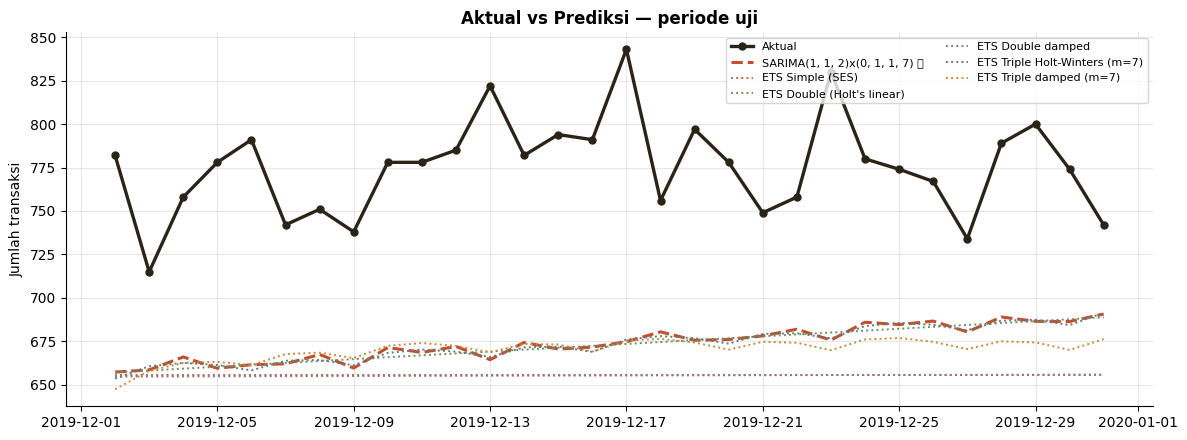

In [ ]:
plt.figure(figsize=(12, 4.5))

# Garis aktual: tebal, dengan titik-titik di tiap hari
plt.plot(test.index, test.values, 'o-', color='#2A2318', lw=2.4, ms=5, label='Aktual')

warna_lain = ['#B96A45', '#6F8F63', '#8C7590', '#5F7A82', '#C68A3D']
i = 0
for nama, p in semua_prediksi.items():
    if nama == model_terbaik:
        # Model terbaik: garis tebal putus-putus, warna mencolok
        plt.plot(test.index, p, color='#C1502E', lw=2.2, ls='--', label=f'{nama} ⭐')
    else:
        # Model lain: garis tipis titik-titik
        plt.plot(test.index, p, ls=':', lw=1.4,
                 color=warna_lain[i % len(warna_lain)], label=nama)
        i += 1

plt.title('Aktual vs Prediksi — periode uji', fontweight='bold')
plt.ylabel('Jumlah transaksi')
plt.legend(fontsize=8, ncol=2)      # ncol=2 -> legenda dibuat 2 kolom biar muat
plt.tight_layout()
plt.show()

### 👀 Cara membaca grafik ini

**Garis hitam tebal** = kenyataan. Semua garis lain adalah **tebakan model**.

Yang perlu kamu perhatikan:

1. Garis mana yang **paling dekat** dengan hitam?
2. Ada model yang **selalu di atas** hitam? → ia **overestimate** (kelebihan tebak)
3. Ada yang **selalu di bawah**? → **underestimate** (kekurangan tebak)

> 🔑 **Error yang konsisten searah lebih berbahaya daripada error acak.**
>
> Kalau model selalu kelebihan tebak, stok akan **selalu** berlebih — dan kerugiannya
> **menumpuk** tiap hari, bukan saling menghapus.
>
> Ini sesuatu yang **tidak terlihat dari angka MAPE saja** — kamu harus melihat
> grafiknya. Itulah kenapa silabus mewajibkan "analisis visual".

In [ ]:
# Cek eksplisit terhadap baseline
mape_terbaik  = evaluasi.loc[model_terbaik, 'MAPE']
mape_baseline = baseline.loc['Baseline naif (lag-7)', 'MAPE']

print(f'MAPE model terbaik : {mape_terbaik:.2f}%')
print(f'MAPE baseline naif : {mape_baseline:.2f}%')
print()

if mape_terbaik <= mape_baseline:
    print('✅ Model mengalahkan baseline — layak dipakai.')
else:
    print('⚠️  Model KALAH dari baseline naif.')
    print('   Tetap laporkan ini. Artinya: untuk data sependek ini, model statistik')
    print('   belum memberi nilai tambah dibanding aturan sederhana "sama seperti')
    print('   minggu lalu". Rekomendasi: kumpulkan data lebih panjang, lalu evaluasi ulang.')

MAPE model terbaik : 12.95%
MAPE baseline naif : 24.26%

✅ Model mengalahkan baseline — layak dipakai.


In [ ]:
def forecast_terbaik(series, nama_model, horizon=HORIZON):
    # Latih ulang model terpilih di seluruh data -> (mean, batas bawah, batas atas)

    if nama_model.startswith('SARIMA'):        # .startswith() -> cek awalan teks
        fit = SARIMAX(series,
                      order=best_order,
                      seasonal_order=best_sorder,
                      enforce_stationarity=False,
                      enforce_invertibility=False).fit(disp=False)
        hasil = fit.get_forecast(horizon)      # get_forecast -> dapat interval juga
        ci = hasil.conf_int()                  # conf_int = confidence interval
        return hasil.predicted_mean, ci.iloc[:, 0], ci.iloc[:, 1]

    # Kalau bukan SARIMA, berarti model ETS
    fit = ExponentialSmoothing(series,
                               initialization_method='estimated',
                               **spesifikasi_ets[nama_model]).fit()
    mean = fit.forecast(horizon)

    # ETS tidak menyediakan interval langsung, jadi kita hitung dari sebaran residual:
    #   fittedvalues = tebakan model untuk data historis
    #   residual     = selisih antara aktual dan tebakan
    #   std          = standar deviasi dari residual itu
    sd = (series - fit.fittedvalues).std()
    return mean, mean - 1.96 * sd, mean + 1.96 * sd    # 1,96 = angka untuk 95%


fc_trx, lo_trx, hi_trx = forecast_terbaik(y, model_terbaik)
lo_trx = lo_trx.clip(lower=0)      # .clip(lower=0) -> jangan sampai negatif,
                                   # karena jumlah transaksi mustahil minus

print(f'Model dipakai : {model_terbaik}')
print(f'Periode       : {fc_trx.index.min().date()} s/d {fc_trx.index.max().date()}')
print()
print(pd.DataFrame({'forecast': fc_trx.round(1),
                    'batas_bawah_95%': lo_trx.round(1),
                    'batas_atas_95%': hi_trx.round(1)}).head(10))

Model dipakai : SARIMA(1, 1, 2)x(0, 1, 1, 7)
Periode       : 2020-01-01 s/d 2020-01-30

            forecast  batas_bawah_95%  batas_atas_95%
2020-01-01     764.6            693.8           835.3
2020-01-02     763.7            684.1           843.3
2020-01-03     760.1            671.7           848.6
2020-01-04     763.7            666.8           860.6
2020-01-05     764.7            659.7           869.7
2020-01-06     764.8            652.2           877.4
2020-01-07     770.1            650.3           890.0
2020-01-08     771.0            643.8           898.2
2020-01-09     771.2            637.3           905.2
2020-01-10     768.4            628.0           908.8


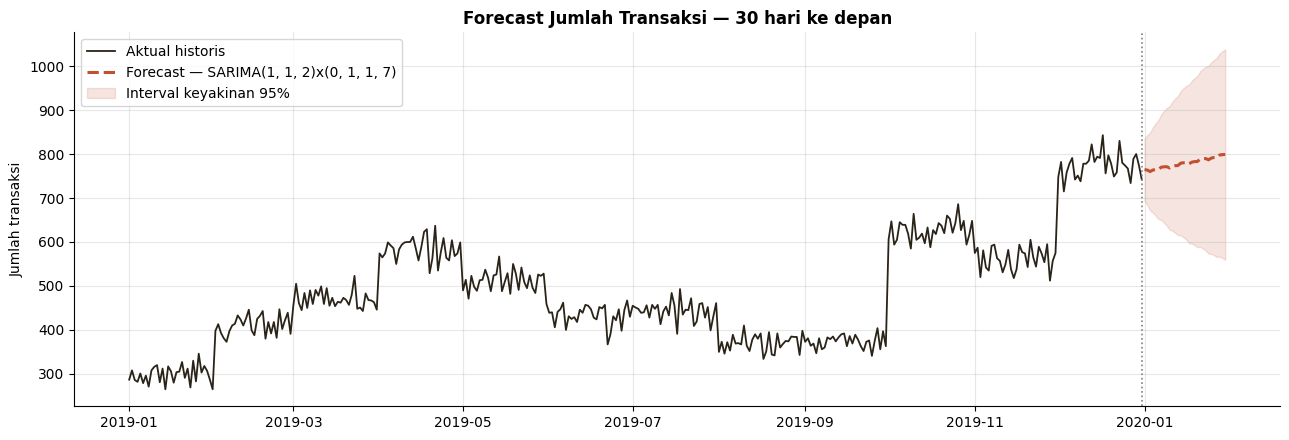

In [ ]:
plt.figure(figsize=(13, 4.5))

# Garis historis
plt.plot(y.index, y.values, color='#2A2318', lw=1.3, label='Aktual historis')

# Garis forecast
plt.plot(fc_trx.index, fc_trx.values, color='#C1502E', lw=2.2, ls='--',
         label=f'Forecast — {model_terbaik}')

# Area interval keyakinan
plt.fill_between(fc_trx.index, lo_trx, hi_trx, color='#C1502E', alpha=0.15,
                 label='Interval keyakinan 95%')

# Garis pemisah antara historis dan forecast
plt.axvline(y.index[-1], color='grey', ls=':', lw=1.2)

plt.title(f'Forecast Jumlah Transaksi — {HORIZON} hari ke depan', fontweight='bold')
plt.ylabel('Jumlah transaksi')
plt.legend()
plt.tight_layout()
plt.show()

## Forecast Visitor

In [ ]:
y_vis = daily['visitor'].astype(float)
train_v, test_v = y_vis[:-HORIZON], y_vis[-HORIZON:]

pred_v = {}

# --- SARIMA untuk visitor ---
fit_sv = SARIMAX(train_v, order=best_order, seasonal_order=best_sorder,
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
pred_v['SARIMA' + str(best_order) + 'x' + str(best_sorder)] = fit_sv.forecast(HORIZON)

# --- Semua varian ETS untuk visitor ---
for nama, spec in spesifikasi_ets.items():
    pred_v[nama] = ExponentialSmoothing(
        train_v, initialization_method='estimated', **spec).fit().forecast(HORIZON)

# --- Evaluasi ---
eval_v = pd.DataFrame(
    {n: hitung_metrik(test_v, p) for n, p in pred_v.items()}
).T.sort_values('MAPE')

print('HASIL EVALUASI — JUMLAH VISITOR (proksi)')
print('-' * 62)
print(eval_v.round(2).to_string())

model_terbaik_v = eval_v.index[0]
print(f'\n⭐ Model terbaik: {model_terbaik_v} '
      f'— MAPE {eval_v.loc[model_terbaik_v,"MAPE"]:.2f}%')

HASIL EVALUASI — JUMLAH VISITOR (proksi)
--------------------------------------------------------------
                                  MAE    RMSE   MAPE
SARIMA(1, 1, 2)x(0, 1, 1, 7)    89.15   93.81  11.41
ETS Triple Holt-Winters (m=7)  101.23  105.23  12.97
ETS Double (Holt's linear)     101.53  105.37  13.01
ETS Triple damped (m=7)        104.11  107.65  13.34
ETS Simple (SES)               118.76  121.98  15.23
ETS Double damped              119.17  122.36  15.28

⭐ Model terbaik: SARIMA(1, 1, 2)x(0, 1, 1, 7) — MAPE 11.41%


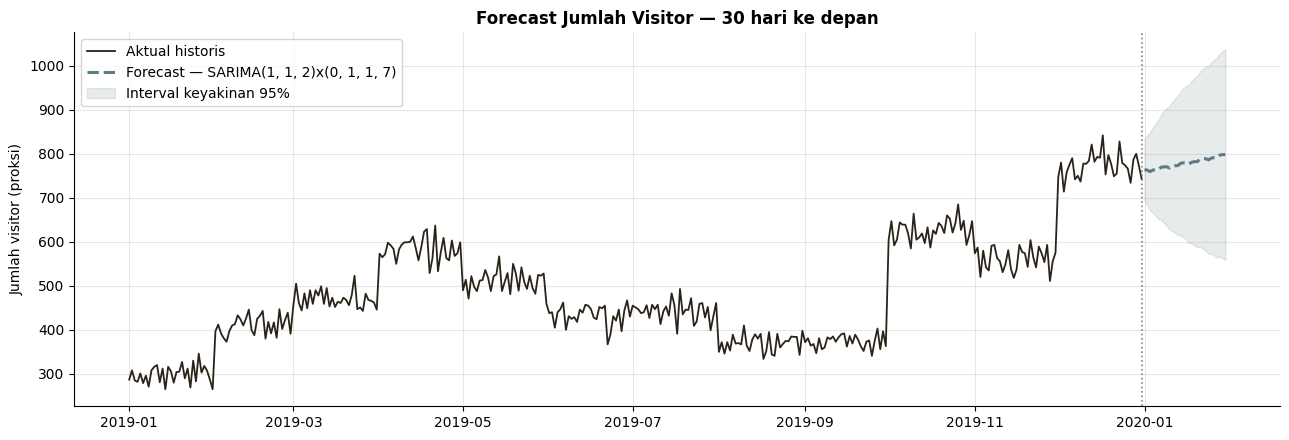

In [ ]:
fc_vis, lo_vis, hi_vis = forecast_terbaik(y_vis, model_terbaik_v)
lo_vis = lo_vis.clip(lower=0)

plt.figure(figsize=(13, 4.5))
plt.plot(y_vis.index, y_vis.values, color='#2A2318', lw=1.3, label='Aktual historis')
plt.plot(fc_vis.index, fc_vis.values, color='#5F7A82', lw=2.2, ls='--',
         label=f'Forecast — {model_terbaik_v}')
plt.fill_between(fc_vis.index, lo_vis, hi_vis, color='#5F7A82', alpha=0.15,
                 label='Interval keyakinan 95%')
plt.axvline(y_vis.index[-1], color='grey', ls=':', lw=1.2)
plt.title(f'Forecast Jumlah Visitor — {HORIZON} hari ke depan', fontweight='bold')
plt.ylabel('Jumlah visitor (proksi)')
plt.legend()
plt.tight_layout()
plt.show()

## ❓ "Kenapa garis forecast-nya hampir datar?"

Model terpilih adalah **SARIMA(1,1,2)x(0,1,1,7)**. Forecast-nya berada di kisaran
**~760–770 transaksi/hari** dan hampir datar, karena:

- Differencing (d = 1) membuat model meneruskan **level terakhir** data (akhir Desember yang tinggi)
- Komponen musiman mingguan **kecil** (amplitudo ~6 transaksi), jadi gelombang mingguannya hampir tidak terlihat

**Ini bukan kelemahan yang disembunyikan.** Model tidak punya cukup bukti bahwa lonjakan
akhir tahun akan terus naik, jadi ia tidak menggambar garis yang terus menanjak.

> 🔑 **Yang memberi informasi soal risiko bukan garisnya, melainkan LEBAR INTERVALNYA.**
>
> Itulah rentang ketidakpastian harian yang sesungguhnya, dan **itulah angka yang
> dipakai** untuk menentukan buffer stok dan kapasitas.

**Yang harus dilakukan tim:**

1. Pakai angka ini untuk perencanaan **2–4 minggu** saja
2. **Retrain tiap minggu** begitu data baru masuk

> ⚠️ Forecast datar yang dibiarkan berumur panjang adalah **tanda bahaya**, bukan
> jawaban akhir.

In [ ]:
# Bandingkan dengan 30 hari terakhir yang sesungguhnya
hist30_trx = y[-HORIZON:].sum()
hist30_vis = y_vis[-HORIZON:].sum()

print('=' * 66)
print(f'  RINGKASAN FORECAST {HORIZON} HARI '
      f'({fc_trx.index.min().date()} s/d {fc_trx.index.max().date()})')
print('=' * 66)
print(f'  TRANSAKSI')
print(f'    Model            : {model_terbaik}')
print(f'    Rata-rata/hari   : {fc_trx.mean():,.0f}  '
      f'(95% CI: {lo_trx.mean():,.0f} – {hi_trx.mean():,.0f})')
print(f'    Total {HORIZON} hari   : {fc_trx.sum():,.0f}')
print(f'    vs {HORIZON} hari lalu : {hist30_trx:,.0f}  '
      f'({(fc_trx.sum()/hist30_trx-1)*100:+.1f}%)')
print()
print(f'  VISITOR (proksi)')
print(f'    Model            : {model_terbaik_v}')
print(f'    Rata-rata/hari   : {fc_vis.mean():,.0f}')
print(f'    Total {HORIZON} hari   : {fc_vis.sum():,.0f}')
print(f'    vs {HORIZON} hari lalu : {hist30_vis:,.0f}  '
      f'({(fc_vis.sum()/hist30_vis-1)*100:+.1f}%)')
print('=' * 66)

  RINGKASAN FORECAST 30 HARI (2020-01-01 s/d 2020-01-30)
  TRANSAKSI
    Model            : SARIMA(1, 1, 2)x(0, 1, 1, 7)
    Rata-rata/hari   : 779  (95% CI: 613 – 945)
    Total 30 hari   : 23,372
    vs 30 hari lalu : 23,256  (+0.5%)

  VISITOR (proksi)
    Model            : SARIMA(1, 1, 2)x(0, 1, 1, 7)
    Rata-rata/hari   : 778
    Total 30 hari   : 23,351
    vs 30 hari lalu : 23,227  (+0.5%)


In [ ]:
# Ambil semua angka dari variabel yang sudah dihitung sebelumnya
kap_normal  = fc_trx.mean()              # kapasitas normal
kap_buffer  = hi_trx.max()               # kapasitas puncak (batas atas 95%)
top_bundel  = top_pasangan.iloc[0, 0]    # pasangan produk teratas
kota_volume = kota.nlargest(1, 'orders').index[0]
kota_aov    = kota.nlargest(1, 'aov').index[0]
jam_rush    = ', '.join(f'{h:02d}.00' for h in sorted(rush))
jam_sepi    = ', '.join(f'{h:02d}.00' for h in sorted(sepi.index))

print('=' * 72)
print('  REKOMENDASI BISNIS')
print('=' * 72)

print('\n  📦 OPERASIONAL & SUPPLY')
print(f'   1. Siapkan kapasitas {kap_normal:,.0f} order/hari,')
print(f'      dengan buffer sampai {kap_buffer:,.0f} (batas atas interval 95%)')
print(f'      agar tidak kehabisan di hari ramai.')
print(f'   2. Prioritaskan stok produk bervolume tertinggi:')
for p in produk.nlargest(3, 'Quantity').index:
    print(f'      - {p}')
print(f'   3. Jadwalkan maintenance & deploy pada jam {jam_sepi}')
print(f'      (jam tersepi, risiko kehilangan transaksi terkecil).')

print('\n  📣 MARKETING & GROWTH')
print(f'   1. Luncurkan bundel: {top_bundel}')
print(f'      (permintaannya sudah terbukti, tinggal dipermudah).')
print(f'   2. Kirim campaign menjelang rush hour: {jam_rush}')
print(f'   3. Segmentasi kota:')
print(f'      - {kota_volume}: mainkan volume & retensi')
print(f'      - {kota_aov}: mainkan produk premium & upsell')
print(f'   4. Target naikkan item/transaksi dari {avg_item:.2f} -> 1,30')
print(f'      lewat cross-sell di halaman checkout.')
print('=' * 72)

  REKOMENDASI BISNIS

  📦 OPERASIONAL & SUPPLY
   1. Siapkan kapasitas 779 order/hari,
      dengan buffer sampai 1,038 (batas atas interval 95%)
      agar tidak kehabisan di hari ramai.
   2. Prioritaskan stok produk bervolume tertinggi:
      - AAA Batteries (4-pack)
      - AA Batteries (4-pack)
      - USB-C Charging Cable
   3. Jadwalkan maintenance & deploy pada jam 02.00, 03.00, 04.00
      (jam tersepi, risiko kehilangan transaksi terkecil).

  📣 MARKETING & GROWTH
   1. Luncurkan bundel: Lightning Charging Cable  +  iPhone
      (permintaannya sudah terbukti, tinggal dipermudah).
   2. Kirim campaign menjelang rush hour: 11.00, 12.00, 13.00, 18.00, 19.00, 20.00
   3. Segmentasi kota:
      - San Francisco (CA 94016): mainkan volume & retensi
      - Atlanta (GA 30301): mainkan produk premium & upsell
   4. Target naikkan item/transaksi dari 1.17 -> 1,30
      lewat cross-sell di halaman checkout.


## ⚠️ Keterbatasan yang WAJIB masuk laporan

**Bagian ini bukan formalitas.** Analis yang menuliskan keterbatasannya adalah analis
yang **bisa dipercaya**. Yang menyembunyikannya akan ketahuan saat forecast-nya meleset
— dan saat itu kredibilitasnya habis.

**1. Panjang data.**
Model dibangun dari 365 hari data (2019) = sekitar 52 siklus mingguan, tetapi hanya
**SATU siklus tahunan**. Satu siklus belum cukup untuk mempelajari pola musiman tahunan
(Black Friday, libur akhir tahun, dll.), jadi model ini **belum bisa memprediksi musiman tahunan**.
→ **Jangan dipakai untuk perencanaan kuartalan** sebelum tersedia data minimal 2–3 tahun.

**2. Visitor adalah proksi, bukan angka asli.**
Kita memakai alamat pembelian unik per hari. Visitor sesungguhnya (termasuk yang cuma
melihat-lihat) pasti jauh lebih banyak, dan **rasio konversinya tidak bisa dihitung**
dari data ini.

**3. Forecast mengasumsikan "business as usual".**
Model tidak tahu akan ada kampanye besar, kompetitor baru, perubahan harga, atau
gangguan supply. Semua itu **harus ditambahkan secara manual** ke perencanaan.

**4. Akurasi menurun seiring horizon.**
Prediksi hari ke-1 jauh lebih bisa dipercaya daripada hari ke-30. Gunakan 2–4 minggu
pertama untuk keputusan operasional, sisanya cuma untuk gambaran kasar.

**5. Zona waktu.**
Analisis rush hour mengasumsikan semua transaksi dalam satu zona waktu. Kalau pembelinya
tersebar (dan di data ini memang begitu), "jam 19.00" adalah **campuran** beberapa waktu
lokal.

**6. Retrain berkala.**
Jalankan ulang notebook ini **setiap minggu** begitu data baru masuk.
**Forecast adalah proses berulang, bukan dokumen sekali jadi.**

# Reflection Question

1. Mengapa penting menganalisis tren waktu (trend & seasonality) sebelum membuat model forecasting, dan bagaimana pengabaian pola musiman bisa memengaruhi keputusan bisnis? Jelaskan dengan contoh bagaimana prediksi yang mengabaikan seasonality dapat menyebabkan salah perencanaan stok atau kampanye pemasaran.

Karena keduanya **menentukan model mana yang boleh dipakai**. Salah diagnosis = salah
model = salah keputusan:

| Kondisi data | Model yang dipilih | Akibatnya |
|---|---|---|
| Ada trend | SES (tanpa trend) | Forecast selalu **tertinggal** di belakang pertumbuhan |
| Ada seasonality | Model tanpa musiman | Jadi **rata-rata datar** — salah di puncak *dan* di lembah |
| Tidak ada seasonality | Holt-Winters dipaksakan | Model **mengarang pola** dari noise (overfitting) |

**Di studi kasus kita**, data punya trend yang kuat dan musiman mingguan yang kecil. Karena itu,
model dengan komponen trend (SARIMA, Holt's linear, Holt-Winters) jauh lebih baik daripada
SES tanpa trend (MAPE ~13% vs ~15%).

---

#### Contoh konkret — toko kue jelang Lebaran

Rata-rata penjualan harian 100 box. Tapi:

- H-7 Lebaran permintaannya **400 box**
- Dua minggu sesudahnya cuma **40 box**

Forecast yang mengabaikan seasonality akan bilang *"100 box tiap hari"*:

| Periode | Stok disiapkan | Permintaan asli | Akibat |
|---|---|---|---|
| **H-7** | 100 | 400 | **300 box lost sale** — kehilangan 75% peluang |
| **Sesudah** | 100 | 40 | **60 box basi** — kerugian langsung |

**Efek berantai ke pemasaran:** kampanye diskon malah dijadwalkan di minggu puncak —
perusahaan **membayar diskon untuk penjualan yang toh akan terjadi**. Sebaliknya minggu
sepi dibiarkan tanpa promosi, padahal justru di situ promo **paling dibutuhkan**.

**Di data kita** efek musimannya kecil, jadi mengabaikannya tidak fatal — **tapi kita
hanya tahu itu SETELAH mengeceknya**, bukan sebelumnya

2. Bagaimana metrik agregasi berbeda (harian, mingguan, bulanan) membantu tim bisnis dalam mengambil keputusan operasional dan strategis? Berikan contoh keputusan yang lebih tepat dibuat dengan data mingguan dibandingkan data harian, atau sebaliknya.

Makin **halus** agregasinya, makin banyak **noise**.
Makin **kasar**, makin banyak **sinyal** tapi makin **lambat** bereaksi.

Tidak ada yang "paling benar" — yang ada adalah **yang cocok untuk keputusannya**.

| Level | Untuk keputusan | Contoh konkret |
|---|---|---|
| **Harian** | Operasional | Jadwal shift kurir besok, kapasitas server, deteksi anomali |
| **Mingguan** | Taktis | Evaluasi kampanye, re-order stok, laporan rutin manajemen |
| **Bulanan** | Strategis | Target kuartalan, ekspansi kota baru, laporan investor |

**Contoh yang lebih tepat MINGGUAN daripada harian:**

Menilai keberhasilan kampanye marketing. Data harian akan **menipu** — naik-turun Sabtu
vs Kamis bisa terlihat seperti *"kampanye berhasil/gagal"*, padahal itu cuma **efek hari**.
Agregasi mingguan **otomatis menetralkan pola 7 hari**.

**Contoh yang lebih tepat HARIAN daripada mingguan:**

Keputusan *"besok butuh berapa kurir"*. Data mingguan datang **terlambat 7 hari** —
sudah tidak berguna untuk keputusan besok.

**Jebakan di level bulanan:**

Jumlah hari berbeda (28–31). Di data kita, pertumbuhan terlihat jauh lebih kecil kalau
hanya membandingkan **total bulanan**, dibanding kalau **dinormalisasi per hari**.
Selalu bandingkan rata-rata harian. (Lihat lagi Q2.)